In [236]:
#Requirements: Wilson's correletion to estimate K-values
 #root finding technique (easiest: bisection method)
 #plot RR function with respect to beta_v
 #compositions and quantities of liquid and vapor at given T, plot

In [237]:
#Requirements: Wilson's correletion to estimate K-values
 #root finding technique (easiest: bisection method)
 #plot RR function with respect to beta_v
 #compositions and quantities of liquid and vapor at given T, plot

In [238]:
import numpy as np
import matplotlib.pyplot as plt

R = 8.314  # J/(mol*K)
T = 341  #K
P = 1700 #kPa

# introduce function Wilson_K to estimate K-values based on Wilson's correlation
# inputs: T, P, Tc(i), Pc(i), omega(i)
# outputs: K(i)
def Wilson_K(T, P, Tc, Pc, omega):
    K = (Pc / P) * np.exp(5.373 * (1 + omega) * (1 - Tc / T))
    return K

#Function RR_Eval
#inputs: beta_v, K(i), z(i)
#outputs: RR = ((1-Ki)*zi)/(1-(1-Ki)*beta_v)
def RR_Eval(beta_v, K, z):
    RR = np.sum(((1 - K) * z) / (1 - (1 - K) * beta_v))
    return RR

#Function Rachford_Rice
#inputs: K(i), z(i)
#outputs: beta_v_root, beta_v_min, beta_v_max, x(i), y(i)
def Rachford_Rice(K, z):
    # Define the function to find the root of
    def RR_function(beta_v):
        return RR_Eval(beta_v, K, z) - 1

    # Find the minimum and maximum beta_v values for root finding
    beta_v_min = max(0, 1 - 1 / np.max(K))
    beta_v_max = min(1, 1 / np.min(K))

    # Check if the function changes sign in the interval [beta_v_min, beta_v_max]
    if RR_function(beta_v_min) * RR_function(beta_v_max) >= 0:
        raise ValueError("The function does not change sign in the interval. Please check your K and z values.")

    # Use bisection method to find the root (beta_v)
    beta_v_root = bisect(RR_function, beta_v_min, beta_v_max)

    # Calculate liquid and vapor compositions
    x = z / (1 + (K - 1) * beta_v_root)
    y = K * x

    return beta_v_root, beta_v_min, beta_v_max, x, y

# plot RR function with respect to beta_v
# beta_v_min and beta_v_max are vertical asymptotes
def plot_RR_function(K, z):
    beta_v_min = max(0, 1 - 1 / np.max(K))
    beta_v_max = min(1, 1 / np.min(K))
    
    beta_v_values = np.linspace(beta_v_min - 0.1, beta_v_max + 0.1, 1000)
    RR_values = [RR_Eval(beta_v, K, z) for beta_v in beta_v_values]

    plt.figure(figsize=(10, 6))
    plt.plot(beta_v_values, RR_values, label='Rachford-Rice Function')
    plt.axvline(x=beta_v_min, color='r', linestyle='--', label='beta_v_min')
    plt.axvline(x=beta_v_max, color='g', linestyle='--', label='beta_v_max')
    plt.xlabel('beta_v')
    plt.ylabel('RR(beta_v)')
    plt.title('Rachford-Rice Function vs beta_v')
    plt.legend()
    plt.grid()
    plt.ylim(-10, 10)  # Adjust y-axis limits for better visualization
    plt.show()

In [239]:
#test code with given data for a binary mixture
#component 1: methane, component 2: n-butane, component 3: n-decane
#mole fraction 1: 0.61, mole fraction 2: 0.28, mole fraction 3: 0.11


In [240]:
#setup no. 2
import numpy as np
import matplotlib.pyplot as plt

Tc = np.array([0,0,0]) #fill
Pc = np.array([0,0,0]) #fill
z = np.array([0,0,0]) #fill
omega = np.array([0,0,0]) #fill

def Wilson_K(T, P, Tc, Pc, omega):
    ###
    K = (Pc / P) * np.exp(5.373 * (1 + omega) * (1 - Tc / T))
    return "K_1 = {}".format(K[0]), "K_2 = {}".format(K[1]), "K_3 = {}".format(K[2])

def RR_Eval(z, K, beta_v):
    RR = np.sum(((1 - K) * z) / (1 - (1 - K) * beta_v))
    ###
    return RR.round(2)

def Rachford_Rice(K, z):
    tol = 1e-6
    max_iter = 100
    beta_v_min = 1 / (1 - np.max(K))
    beta_v_max = 1 / (1 - np.min(K))
    beta_v_l = beta_v_min
    beta_v_h = beta_v_max
    iteration = 1
    beta_v = (beta_v_min + beta_v_max) / 2

    beta_v = (beta_v_min + beta_v_max) / 2
    for iteration in range(max_iter):
        RR = RR_Eval(z, K, beta_v)
        if abs(RR) < tol:
            break
        if RR > 0 + tol:
            beta_v_h = beta_v
        if RR < 0 - tol:
            beta_v_l = beta_v
        beta_v = (beta_v_l + beta_v_h) / 2
        iteration += 1
        #BISECTION METHOD  
            
    x = z / (1 + (K - 1) * beta_v)
    y = K * x
    return "Beta_V,root = {}, Beta_V,min = {}, Beta_V,max = {}, X_V = {}, X_L = {}".format(
        beta_v.round(2), beta_v_min.round(2), beta_v_max.round(2), y.round(2), x.round(2))

def plot_RR_function(K, z):
    beta_v_min = 1 / (1 - np.max(K))
    beta_v_max = 1 / (1 - np.min(K))
    
    beta_v_values = np.linspace(beta_v_min + 1e-6, beta_v_max - 1e-6, 1000)
    RR_values = [RR_Eval(z, K, beta_v) for beta_v in beta_v_values]

    plt.figure(figsize=(10, 6))
    plt.plot(beta_v_values, RR_values, label='Rachford-Rice Function')
    plt.axvline(x=beta_v_min, color='r', linestyle='--', label='beta_v_min')
    plt.axvline(x=beta_v_max, color='g', linestyle='--', label='beta_v_max')
    plt.axhline(y=0, color='k', linestyle='-')
    plt.xlabel('beta_v')
    plt.ylabel('RR(beta_v)')
    plt.title('Rachford-Rice Function vs Beta_V')
    plt.legend()
    plt.grid()
    plt.ylim(-10, 10)  # Adjust y-axis limits for better visualization
    plt.show()

In [241]:
#test code with given data for a ternary mixture
Wilson_K(341, 1700, np.array([190.6, 425.3, 594.2]),
         np.array([4600, 3800, 2478]), np.array([.008,.193,.574]))


('K_1 = 29.49376151170249',
 'K_2 = 0.45828377360428857',
 'K_3 = 0.002731892437201933')

In [242]:
RR_Eval(np.array([0.61, 0.28, 0.11]), np.array([29.49, 0.46, 0.00]), 0.77)
#reverse plugging to see if solution beta_v returns a value close to zero. Pretty close.
#very close to zero, this equation is good

np.float64(-0.02)

In [243]:
Rachford_Rice(np.array([29.7, 0.45, 0.00]), np.array([0.61, 0.28, 0.11]))
# numbers look correct. format all fxns to return text
    # (i.e. "Beta_V,root = ", "Beta_V,min = ", "Beta_V,max = ", "X_V = ", "X_L = ")
    # round to two decimal places for better readability

'Beta_V,root = 0.77, Beta_V,min = -0.03, Beta_V,max = 1.0, X_V = [0.78 0.22 0.  ], X_L = [0.03 0.49 0.49]'

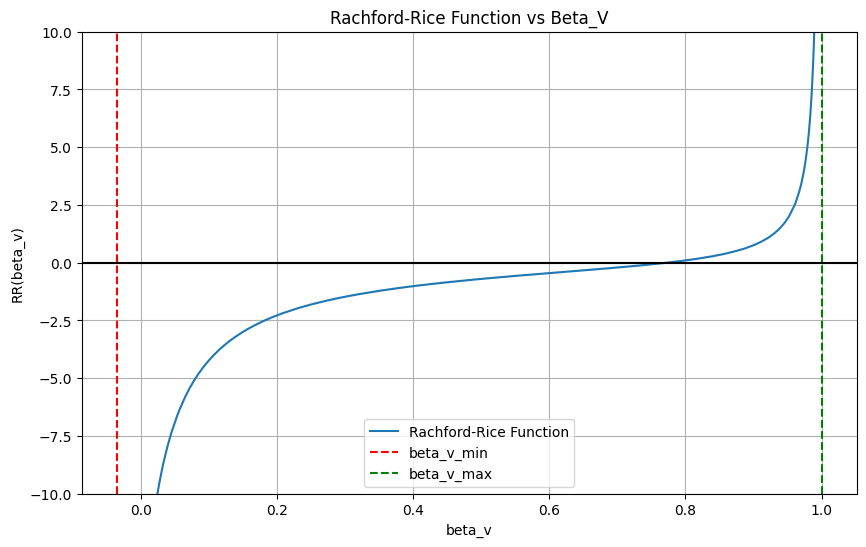

In [244]:
plot_RR_function(np.array([29.7, 0.45, 0.00]), np.array([0.61, 0.28, 0.11]))